In [1]:
import pandas as pd
import numpy as np



df = pd.read_csv("encuesta_sueca.csv", sep=";", encoding="utf-8")


In [2]:
df.head()

,Estado civil,Ciudadano sueco,zona,Género,¿Cuántos años tienes?,Niveles de formación,Trabajo,Número en el hogar,Número de menores de 18 años en el hogar,¿Qué tipo de vivienda estás viviendo?,...,Participación en ingresos - Vivienda,"Porcentaje de ingresos - Ropa, artículos de modalidad",Participación en ingresos - Actividades de tiempo libre,Participación en ingresos - Servicios de servicios domésticos,El importe de los ingresos - Servicios digitales,Participación en ingresos - Ahorro,Porcentaje de ingresos - Otros,Ahorros: ¿fondos con etiqueta ecológica/éticos?,El mayor impacto climático,Cambiar para reducir los impactos climáticos
0,S.,N,Teg,Hombre,50-64,Colegio de formación profesional,Trabajadores en el sector de la salud,3.0,1.0,Contrato de arrendamiento,...,30.0,1.0,3.0,0.0,4.0,10.0,28.0,0.0,Su elección de alimentos,Comer más vegetariano
1,G,J,Backen-Västerslätt,Mujer,65+,Universidad/universidad de enseñanza superior,Jubilado,2.0,0.0,Villa,...,0.0,20.0,0.0,10.0,10.0,20.0,10.0,0.0,Sus viajes en coche,Comer más vegetariano
2,S.,J,Rural interior,Hombre,30-49,Primaria y secundaria.,Otros,2.0,0.5,Villa,...,45.0,10.0,0.0,0.0,2.0,13.0,0.0,0.0,Sus viajes en coche,Conducir un coche más pequeño.
3,G,J,Ciudad del Este,Mujer,50-64,Universidad/universidad de enseñanza superior,Empleo remunerado a tiempo completo,3.0,0.0,Casa adosada,...,10.0,8.0,2.0,0.0,1.0,20.0,9.0,0.0,Su consumo de ropa y artículos,No hay nada.
4,Y,J,Áreas exteriores,Mujer,20-29,Primaria y secundaria.,Estudiantes de la escuela,4.0,0.0,Villa,...,0.0,0.0,10.0,0.0,0.0,0.0,0.0,0.0,Ninguno de los anteriores:,No hay nada.


Ací tenim les dades d'una enquesta sobre hàbits de consum en Suècia. 

Està traduïda i adaptada del suec i les dades originals estan a un CSV a aquest directori. Gran part de la neteja de les dades s'ha fet, falta imputar dades que falten i convertir columnes al format adequat per a entrenar models. 

Al `.head()` no es veuen totes les columnes.

> Raona quines adaptacions s'han de fet al dataset per poder entrenar models de machine learning. Imputa, estandaritza, transforma categories. Justifica les decisions

> Amb el dataset adaptat, tria una variable que consideres adequada per a fer una regressió.

> Crea un procés complet d'entrenament per a la regressió amb: Anàlisi de correlacions i informació mútua, Eliminació de variables no rellevants, Detecció de outliers, tria del tipus de model, tria d'hiperparàmetres amb Grid Search i cross-validation, entrenament, avaluació, gràfiques d'avaluació i conclusions.

In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1475 entries, 0 to 1474
Columns: 147 entries, Estado civil to Cambiar para reducir los impactos climáticos
dtypes: float64(97), int64(26), object(24)
memory usage: 1.7+ MB


In [13]:
from sklearn.feature_selection import mutual_info_regression

mi_scores = mutual_info_regression(, y)


Número de automóviles en el hogar
1.0                                  811
2.0                                  361
0.0                                  219
4.0                                   82
Name: count, dtype: int64

In [20]:
df.select_dtypes(include=["object"]).columns

Index(['Estado civil', 'Ciudadano sueco', 'zona', 'Género',
       '¿Cuántos años tienes?', 'Niveles de formación', 'Trabajo',
       '¿Qué tipo de vivienda estás viviendo?', 'Lugar de compra',
       'Número de compras/semana', 'Planifica la compra',
       'Las operaciones más frecuentes', 'Almuerzo/noche en la calle.',
       'Negocios de ropa menor', 'Compras de ropa más gruesa',
       'Negocios de piezas exteriores', 'Acta por otro lado',
       'Comercio de zapatos', 'Compras de deportes y aficiones',
       'Fuente de calor del hogar', 'Tipo de electricidad en el hogar',
       'Acceso a viviendas de recreo',
       'Tipo de electricidad en viviendas recreativas',
       '¿Qué tipo de combustible se utiliza en este vehículo?',
       'Acceso a coche compartido cerca de casa.',
       'El comportamiento cotidiano', 'En eventos culturales.',
       'Ejercicio en gimnasio', 'Disfruta de servicios domésticos',
       'Cerca de la estación de reciclaje', 'El mayor impacto climático'

In [58]:
correlacions = df.select_dtypes(include=["float64","int64"]).corr()
mes_correlacionats = correlacions[abs(correlacions["Número en el hogar"])>0.2].index
df_correlacionats=df[mes_correlacionats] 
df_correlacionats= df_correlacionats + np.random.uniform(0, 0.5, df_correlacionats.shape)

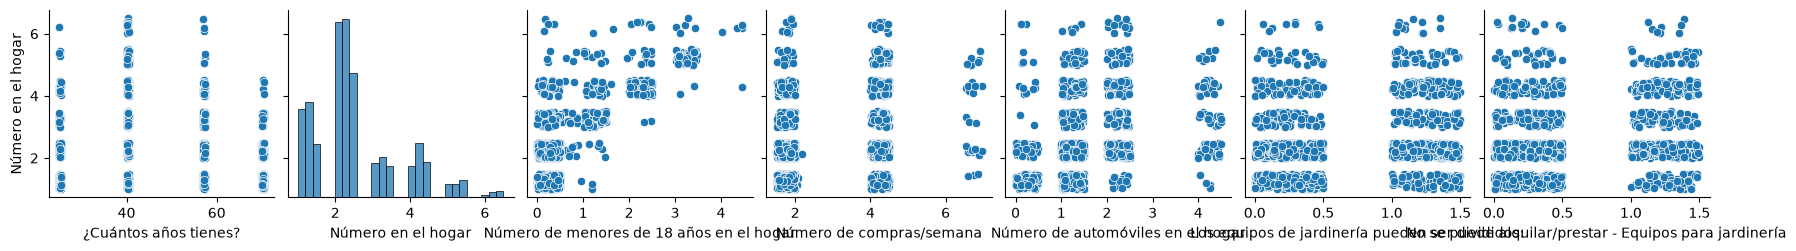

In [59]:
import seaborn as sns
sns.pairplot(data=df_correlacionats, y_vars="Número en el hogar" )

In [35]:
df["¿Cuántos años tienes?"] = pd.to_numeric(df["¿Cuántos años tienes?"].replace({"65+":"70", "50-64":"57", "30-49": "40", "20-29": "25"}), errors="coerce").fillna(40)

In [39]:
df['Número de compras/semana'] = pd.to_numeric(df['Número de compras/semana'].replace({"6-7":6.5}), errors="coerce").fillna(2)

In [43]:
df["Compras de deportes y aficiones"] = pd.to_numeric(df["Compras de deportes y aficiones"].replace({"Más raramente o nunca.":"0","Una vez al año.":"1","Algunas veces al año.":"6","Una vez al mes.":"12","Muchas veces al mes o más a menudo.":"48"}), errors="coerce").fillna(2)

In [46]:
df["Negocios de ropa menor"] = pd.to_numeric(df["Negocios de ropa menor"].replace({"Más raramente o nunca.":"0","Una vez al año.":"1","Algunas veces al año.":"6","Una vez al mes.":"12","Muchas veces al mes o más a menudo.":"48"}), errors="coerce").fillna(2)

In [50]:
df["Compras de ropa más gruesa"] = pd.to_numeric(df["Compras de ropa más gruesa"].replace({"Más raramente o nunca.":"0","Una vez al año.":"1","Algunas veces al año.":"6","Una vez al mes.":"12","Muchas veces al mes o más a menudo.":"48"}), errors="coerce").fillna(2)

In [51]:
df["Negocios de piezas exteriores"] = pd.to_numeric(df["Negocios de piezas exteriores"].replace({"Más raramente o nunca.":"0","Una vez al año.":"1","Algunas veces al año.":"6","Una vez al mes.":"12","Muchas veces al mes o más a menudo.":"48"}), errors="coerce").fillna(2)

In [53]:
df["Acta por otro lado"] = pd.to_numeric(df["Acta por otro lado"].replace({"Más raramente o nunca.":"0","Una vez al año.":"1","Algunas veces al año.":"6","Una vez al mes.":"12","Muchas veces al mes o más a menudo.":"48"}), errors="coerce").fillna(2)

In [54]:
df["Comercio de zapatos"] = pd.to_numeric(df["Comercio de zapatos"].replace({"Más raramente o nunca.":"0","Una vez al año.":"1","Algunas veces al año.":"6","Una vez al mes.":"12","Muchas veces al mes o más a menudo.":"48"}), errors="coerce").fillna(2)

In [62]:
df_onehot = pd.get_dummies(df, columns=df.select_dtypes(include=["object"]).columns, prefix_sep='_' , drop_first=True)

In [63]:
df_onehot.head()

,¿Cuántos años tienes?,Número en el hogar,Número de menores de 18 años en el hogar,¿Ingresos mensuales antes de impuestos?,Número de compras/semana,La proximidad a la tienda.,Lo importante es el estacionamiento.,parada de autobús.,Horarios de apertura,Precio de las mercancías,...,El mayor impacto climático_Sus viajes aéreos,El mayor impacto climático_Sus viajes en coche,Cambiar para reducir los impactos climáticos_Bajar la temperatura del interior en el hogar.,Cambiar para reducir los impactos climáticos_Comer más vegetariano,Cambiar para reducir los impactos climáticos_Comprar menos ropa y artículos de moda.,Cambiar para reducir los impactos climáticos_Conducir un coche más pequeño.,Cambiar para reducir los impactos climáticos_Ninguno de los anteriores:,Cambiar para reducir los impactos climáticos_No hay nada.,"Cambiar para reducir los impactos climáticos_Otro, es decir: cambiar de trabajo.",Cambiar para reducir los impactos climáticos_Realizar menos o menos viajes aéreos.
0,57.0,3.0,1.0,0.0,1.5,0,0,0,0,1,...,False,False,False,True,False,False,False,False,False,False
1,70.0,2.0,0.0,0.0,1.5,1,0,0,0,1,...,False,True,False,True,False,False,False,False,False,False
2,40.0,2.0,0.5,0.0,4.0,1,1,0,1,1,...,False,True,False,False,False,True,False,False,False,False
3,57.0,3.0,0.0,39100.0,1.5,0,1,0,0,0,...,False,False,False,False,False,False,False,True,False,False
4,25.0,4.0,0.0,0.0,4.0,0,0,0,1,0,...,False,False,False,False,False,False,False,True,False,False


In [72]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

X = df_onehot.drop("Número en el hogar",axis=1)
y = df_onehot["Número en el hogar"].fillna(1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, y_train.shape)


pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", DecisionTreeRegressor())
])

scores = cross_val_score(pipeline, X_train, y_train, cv=5)
print("Scores: %s" % scores)
print("%0.2f R² with a standard deviation of %0.2f" % (scores.mean(), scores.std()))


(1180, 220) (1180,)
Scores: [0.29735881 0.38353785 0.4228737  0.59379922 0.39900407]
0.42 R² with a standard deviation of 0.10


In [73]:
# Graella amb MÉS de 2 hiperparàmetres
param_grid = {
    "model__max_depth": [None, 5, 10, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__max_features": ['sqrt', 'log2', 1.0] # 1.0 equival a 'auto' (totes les característiques)
}

# Configuració del GridSearchCV
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(X_train, y_train)

print("Millors paràmetres trobats: %s" % grid_search.best_params_)
print("Millor R² de validació: %0.2f" % grid_search.best_score_)

Millors paràmetres trobats: {'model__max_depth': 5, 'model__max_features': 1.0, 'model__min_samples_split': 10}
Millor R² de validació: 0.61


In [75]:
best_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", DecisionTreeRegressor(max_depth=5,max_features=1.0,min_samples_split=10))
])
best_pipeline.fit(X_train, y_train)
y_pred = best_pipeline.predict(X_test)

from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_log_error

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test,y_pred)
mape = mean_absolute_percentage_error(y_test,y_pred)

print("MSE",mse)
print("RMSE",rmse)
print("R²",r2)
print("MAE",mae)
print("MAPE",mape)

MSE 0.5674437773500909
RMSE 0.7532886414582998
R² 0.6421453489000126
MAE 0.47159252439571314
MAPE 0.25204535565824376


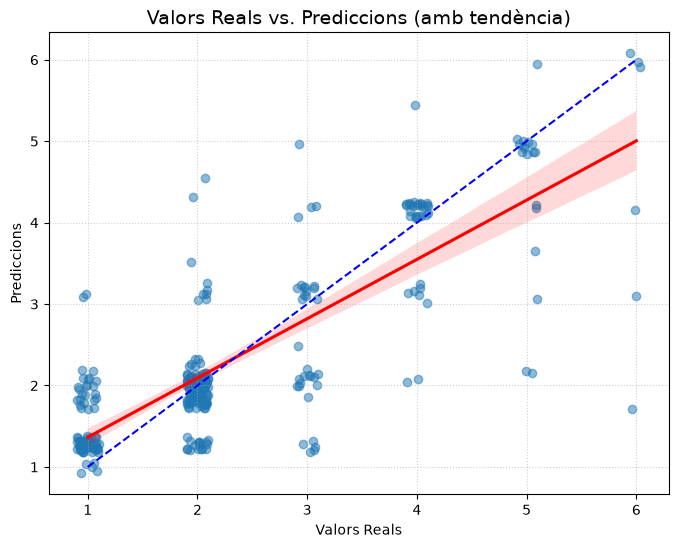

In [81]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Dibuixa els punts i la línia de tendència ajustada
sns.regplot(x=y_test, y=y_pred, scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'}, x_jitter=0.1, y_jitter=0.1)

# Afegim la línia diagonal perfecta (y = x)
valors_min = min(min(y_test), min(y_pred))
valors_max = max(max(y_test), max(y_pred))
plt.plot([valors_min, valors_max], [valors_min, valors_max], color='blue', linestyle='--', label='Model perfecte (y=x)')


plt.title('Valors Reals vs. Prediccions (amb tendència)', fontsize=14)
plt.xlabel('Valors Reals')
plt.ylabel('Prediccions')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

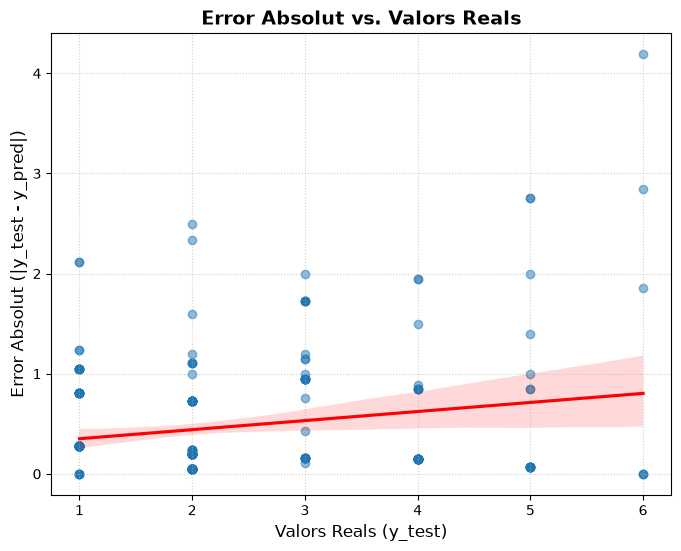

In [82]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))

# 1. Crear el diagrama de dispersió (Scatter plot)

sns.regplot(x=y_test, y=abs(y_test - y_pred), scatter_kws={'alpha': 0.5}, line_kws={'color': 'red'})

# 3. Personalitzar el gràfic
plt.title('Error Absolut vs. Valors Reals', fontsize=14, fontweight='bold')
plt.xlabel('Valors Reals (y_test)', fontsize=12)
plt.ylabel('Error Absolut (|y_test - y_pred|)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)

# Mostrar el gràfic
plt.show()

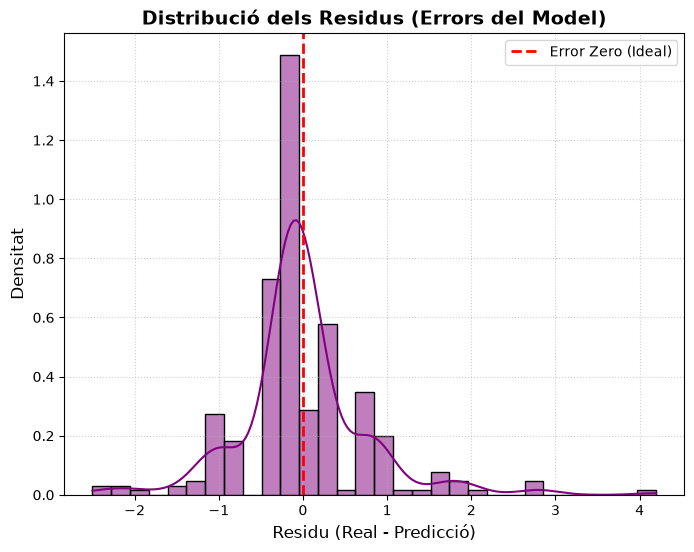

In [83]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Calcular els residus (Valors reals menys prediccions)
residus = y_test - y_pred

# 2. Crear la figura
plt.figure(figsize=(8, 6))

# 3. Dibuixar l'histograma amb la corba de densitat (KDE)
sns.histplot(residus, kde=True, color='purple', bins=30, stat="density")

# 4. Afegir una línia vertical discontínua al 0 (on hauria d'estar centrat l'error ideal)
plt.axvline(0, color='red', linestyle='--', linewidth=2, label='Error Zero (Ideal)')

# 5. Personalitzar el gràfic
plt.title('Distribució dels Residus (Errors del Model)', fontsize=14, fontweight='bold')
plt.xlabel('Residu (Real - Predicció)', fontsize=12)
plt.ylabel('Densitat', fontsize=12)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

plt.show()